# 04 — Évaluation finale sur le jeu de test officiel

**Objectif** : mesurer les modèles retenus sur des moteurs qui n'ont servi à aucun choix, puis comprendre où et pourquoi ils se trompent.

**Questions**
1. Le réseau retenu fait-il mieux que le Random Forest réglé sur le jeu de test ? (suite de l'hypothèse H7)
2. La précision est-elle meilleure près de la panne, là où la prédiction est utile ?
3. La tête de classification apporte-t-elle quelque chose par rapport à un simple seuil sur la RUL prédite ?
4. Le modèle s'appuie-t-il sur les capteurs que l'analyse exploratoire désignait ?

**Protocole**
- Tous les choix ont été figés sur la validation (`03_experiences.ipynb`).
- Dans le jeu de test, chaque série s'arrête avant la panne. On prédit la RUL sur la **dernière fenêtre** de chaque moteur et on compare à `RUL_FDxxx.txt`.
- La vraie RUL de test est **plafonnée à 125**, comme la cible d'entraînement (la section 2 chiffre l'effet de cette convention).
- **Incertitude** : intervalle de confiance à 95 % par *bootstrap* sur les moteurs (10 000 rééchantillonnages). Pour comparer deux modèles, on rééchantillonne l'**écart apparié** de RMSE sur les mêmes moteurs : si l'intervalle ne contient pas 0, l'écart ne s'explique pas par le tirage des moteurs de test.

**Transparence** : pendant la mise au point de ce notebook, les scores de test ont été affichés plusieurs fois. Aucun hyperparamètre n'a été modifié après les avoir vus.

In [1]:
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

# Le notebook est rangé dans notebooks/ : on se place à la racine du projet,
# pour que les chemins relatifs (data/raw, results, models) fonctionnent partout.
PROJECT_ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(PROJECT_ROOT)
sys.path.insert(0, str(PROJECT_ROOT))

from src.utils import set_plot_style

set_plot_style()
pd.set_option("display.max_columns", 30)
pd.set_option("display.width", 200)


def say(text: str) -> None:
    """Affiche une phrase dont les chiffres viennent du code, pas d'une saisie manuelle."""
    from IPython.display import Markdown, display

    display(Markdown(text))

from src.data import prepare
from src.experiments import EXPERIMENTS
from src.train import apply_overrides
from src.utils import load_config


def bundle_for(name: str, **data_overrides) -> dict:
    """Données (découpage, normalisation, fenêtres) de l'expérience `name` du registre."""
    _, base, overrides = EXPERIMENTS[name]
    cfg = apply_overrides(load_config(base), overrides | {f"data.{k}": v for k, v in data_overrides.items()})
    return prepare(cfg["data"], cfg["seed"])

from IPython.display import display
from sklearn.metrics import ConfusionMatrixDisplay, confusion_matrix

from src.baselines import BOOSTING, FOREST, forest_params, run_baselines
from src.data import SENSOR_NAMES, STATE_NAMES, load_test, rul_to_state, windows_for
from src.evaluate import (
    bootstrap_rmse,
    classification_metrics,
    load_run,
    permutation_importance,
    predict,
    regression_metrics,
    test_predictions,
)

SEEDS = range(5)
FINAL_FD001, FINAL_FD004 = "gru_best_fd001", "multitask_w40_fd004"  # choisis sur la validation

## 1. Scores de test

Réseaux et baselines dans le même tableau, 5 graines chacun. Les baselines utilisent la fenêtre W = 40 et les hyperparamètres réglés sur la validation. La dernière colonne compare chaque modèle au Random Forest réglé, sur les mêmes moteurs.

In [2]:
MODELS = {
    "FD001": {"MLP (W=30)": "mlp_fd001", "LSTM (W=30)": "lstm_fd001", "GRU (W=30)": "gru_fd001",
              "LSTM (W=40)": "lstm_best_fd001", "GRU retenu (W=40)": "gru_best_fd001"},
    "FD004": {"GRU multi-tâche (W=30)": "multitask_fd004", "GRU régression seule (W=30)": "abl_monotask",
              "GRU régression seule (W=40)": "abl_monotask_w40", "GRU multi-tâche retenu (W=40)": "multitask_w40_fd004"},
}
FINALS = {"FD001": "GRU retenu (W=40)", "FD004": "GRU multi-tâche retenu (W=40)"}

PREDS, TARGETS = {}, {}
for subset, models in MODELS.items():
    bundle = bundle_for(FINAL_FD001 if subset == "FD001" else FINAL_FD004)
    cfg = bundle["cfg"]
    test_windows = windows_for(load_test(cfg), bundle["scaler"], cfg, last_only=True)
    TARGETS[subset] = test_windows["rul"]
    per_seed = [run_baselines(bundle["train"], {"test": test_windows}, seed=s, forest=forest_params(subset)).set_index("modèle")["pred"]
                for s in SEEDS]
    for name in per_seed[0].index:
        PREDS[subset, name] = np.stack([p[name] for p in per_seed])
    for label, name in models.items():
        PREDS[subset, label] = np.stack([test_predictions(name, s)[1] for s in SEEDS])

rows = []
for (subset, label), preds in PREDS.items():
    y = TARGETS[subset]
    rmse, low, high = bootstrap_rmse(y, preds)
    d, d_low, d_high = bootstrap_rmse(y, preds, PREDS[subset, FOREST])
    per_seed = pd.DataFrame([regression_metrics(y, p) for p in preds])
    rows.append({"jeu": subset, "modèle": label, "rmse": rmse, "ic_bas": low, "ic_haut": high,
                 "mae": per_seed["mae"].mean(), "nasa": per_seed["nasa"].mean(),
                 "ecart_rf": d, "ecart_bas": d_low, "ecart_haut": d_high})
scores = pd.DataFrame(rows).sort_values(["jeu", "rmse"], ascending=[True, False])
scores.round(3).to_csv("results/test_scores.csv", index=False)

affichage = pd.DataFrame({
    "RMSE [IC 95 %]": scores.apply(lambda r: f"{r.rmse:.2f} [{r.ic_bas:.2f} ; {r.ic_haut:.2f}]", axis=1),
    "MAE": scores["mae"].round(2),
    "score NASA": scores["nasa"].round(0).astype(int),
    "écart de RMSE avec le RF réglé [IC 95 %]": scores.apply(
        lambda r: "—" if r["modèle"] == FOREST else f"{r.ecart_rf:+.2f} [{r.ecart_bas:+.2f} ; {r.ecart_haut:+.2f}]", axis=1),
})
affichage.index = pd.MultiIndex.from_frame(scores[["jeu", "modèle"]])
affichage

RMSE [IC 95 %]    MAE  score NASA écart de RMSE avec le RF réglé [IC 95 %]
jeu   modèle                                                                                                                    
FD001 Moyenne du train                         40.21 [36.62 ; 43.63]  35.40       14026                 +27.96 [+23.23 ; +32.68]
      Régression linéaire (dernier cycle)      20.17 [17.51 ; 22.80]  16.18         902                   +7.92 [+5.03 ; +11.06]
      LSTM (W=30)                              14.71 [12.10 ; 17.26]  10.82         499                    +2.46 [+0.33 ; +4.74]
      MLP (W=30)                               14.67 [12.32 ; 17.02]  11.41         394                    +2.42 [+0.18 ; +4.66]
      GRU (W=30)                               14.08 [11.50 ; 16.53]  10.30         386                    +1.83 [-0.25 ; +3.98]
      LSTM (W=40)                              13.13 [10.70 ; 15.53]   9.48         337                    +0.88 [-0.64 ; +2.41]
      GRU retenu (W=40)                        12.74 [10.60 ; 14.86]   9.32         273                    +0.49 [-0.94 ; +2.02]
      Gradient boosting (features de fenêtre)  12.46 [10.23 ; 14.61]   9.03         255                    +0.21 [-0.54 ; +0.96]
      Random Forest (features de fenêtre)      12.25 [10.05 ; 14.43]   8.97         249                                        —
FD004 Moyenne du train                         43.98 [41.23 ; 46.67]  37.77       93201                 +29.98 [+26.52 ; +33.54]
      Régression linéaire (dernier cycle)      25.23 [23.30 ; 27.06]  20.69        4373                  +11.22 [+9.10 ; +13.36]
      GRU multi-tâche (W=30)                   14.76 [13.15 ; 16.46]  11.10         932                    +0.76 [-0.21 ; +1.75]
      Gradient boosting (features de fenêtre)  14.72 [12.82 ; 16.63]  10.35        1021                    +0.72 [+0.03 ; +1.45]
      GRU régression seule (W=30)              14.43 [12.61 ; 16.23]  10.37        1004                    +0.42 [-0.56 ; +1.40]
      GRU multi-tâche retenu (W=40)            14.08 [12.38 ; 15.87]  10.36         871                    +0.07 [-0.84 ; +0.97]
      Random Forest (features de fenêtre)      14.01 [12.27 ; 15.72]  10.01         869                                        —
      GRU régression seule (W=40)              13.88 [12.17 ; 15.57]  10.10         871                    -0.13 [-0.99 ; +0.73]

### Réponse à la question 1

**FD001** (100 moteurs) — réseau retenu : RMSE 12.74 [10.60 ; 14.86] ; Random Forest réglé : 12.25 [10.05 ; 14.43] ; écart +0.49 [-0.94 ; +2.02]. Verdict : l'écart **n'est pas significatif** : l'intervalle contient 0.

**FD004** (248 moteurs) — réseau retenu : RMSE 14.08 [12.38 ; 15.87] ; Random Forest réglé : 14.01 [12.27 ; 15.72] ; écart +0.07 [-0.84 ; +0.97]. Verdict : l'écart **n'est pas significatif** : l'intervalle contient 0.

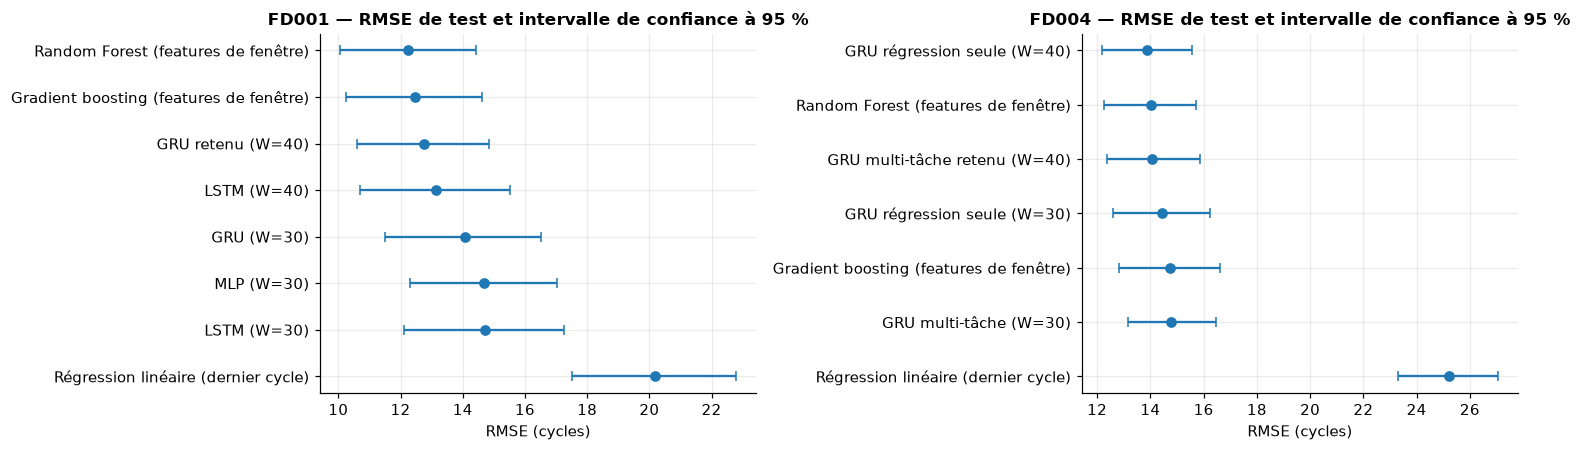

In [3]:
for subset, label in FINALS.items():
    r = scores[(scores["jeu"] == subset) & (scores["modèle"] == label)].iloc[0]
    rf = scores[(scores["jeu"] == subset) & (scores["modèle"] == FOREST)].iloc[0]
    if r.ecart_bas > 0:
        verdict = "le Random Forest réglé est **significativement meilleur**"
    elif r.ecart_haut < 0:
        verdict = "le réseau est **significativement meilleur**"
    else:
        verdict = "l'écart **n'est pas significatif** : l'intervalle contient 0"
    say(f"**{subset}** ({len(TARGETS[subset])} moteurs) — réseau retenu : RMSE {r.rmse:.2f} [{r.ic_bas:.2f} ; {r.ic_haut:.2f}] ; "
        f"Random Forest réglé : {rf.rmse:.2f} [{rf.ic_bas:.2f} ; {rf.ic_haut:.2f}] ; écart {r.ecart_rf:+.2f} "
        f"[{r.ecart_bas:+.2f} ; {r.ecart_haut:+.2f}]. Verdict : {verdict}.")

fig, axes = plt.subplots(1, 2, figsize=(14, 4.2))
for ax, (subset, g) in zip(axes, scores[scores["modèle"] != "Moyenne du train"].groupby("jeu")):
    g = g.sort_values("rmse")
    ax.errorbar(g["rmse"], g["modèle"], xerr=[g["rmse"] - g["ic_bas"], g["ic_haut"] - g["rmse"]], fmt="o", capsize=3)
    ax.invert_yaxis()
    ax.set_title(f"{subset} — RMSE de test et intervalle de confiance à 95 %")
    ax.set_xlabel("RMSE (cycles)")
plt.tight_layout()
fig.savefig("assets/scores_test.png", dpi=150, bbox_inches="tight")
plt.show()

**Comment lire ces intervalles**
- Les intervalles de RMSE des différents modèles se recouvrent largement : avec 100 à 250 moteurs de test, la RMSE d'un modèle n'est connue qu'à environ deux cycles près.
- Deux intervalles qui se recouvrent ne suffisent pas à conclure à l'égalité. C'est l'intervalle de l'**écart apparié** (dernière colonne du tableau) qui tranche, car les deux modèles sont évalués sur les mêmes moteurs.
- La moyenne du train n'est pas tracée : elle est très loin des autres.

## 2. Effet du plafond sur le score

Les deux conventions (RUL de test plafonnée ou non) existent dans la littérature. On mesure ce que la convention change, pour savoir à quoi comparer ces scores.

In [4]:
rows = []
for label, name in [("FD001 — GRU retenu", FINAL_FD001), ("FD004 — modèle final", FINAL_FD004)]:
    capped, uncapped = [], []
    for s in SEEDS:
        w, pred, _ = test_predictions(name, s)
        truth = load_test(load_run(name, s)[1]["cfg"]).groupby("unit")["rul_linear"].last().to_numpy()
        capped.append(regression_metrics(w["rul"], pred)["rmse"])
        uncapped.append(regression_metrics(truth, pred)["rmse"])
    rows.append({"modèle": label, "RMSE, RUL de test plafonnée à 125": np.mean(capped),
                 "RMSE, RUL de test non plafonnée": np.mean(uncapped),
                 "moteurs de test avec RUL > 125": f"{(truth > 125).mean():.0%}"})
cap = pd.DataFrame(rows).set_index("modèle")
display(cap.round(2))
for label, r in cap.iterrows():
    say(f"**{label}** : {r['moteurs de test avec RUL > 125']} des moteurs de test ont une RUL réelle supérieure à 125 ; "
        f"la RMSE passe de {r['RMSE, RUL de test plafonnée à 125']:.1f} à {r['RMSE, RUL de test non plafonnée']:.1f} sans plafond.")

,"RMSE, RUL de test plafonnée à 125","RMSE, RUL de test non plafonnée",moteurs de test avec RUL > 125
modèle,,,
FD001 — GRU retenu,12.74,14.08,11%
FD004 — modèle final,14.08,27.13,27%


**FD001 — GRU retenu** : 11% des moteurs de test ont une RUL réelle supérieure à 125 ; la RMSE passe de 12.7 à 14.1 sans plafond.

**FD004 — modèle final** : 27% des moteurs de test ont une RUL réelle supérieure à 125 ; la RMSE passe de 14.1 à 27.1 sans plafond.

Un modèle entraîné sur une cible plafonnée ne peut pas prédire au-delà du plafond. L'écart entre les deux colonnes n'est donc pas une dégradation du modèle, mais un changement de règle de mesure. Avant toute comparaison avec un article, il faut vérifier quelle convention il utilise.

## 3. RUL prédite contre RUL réelle

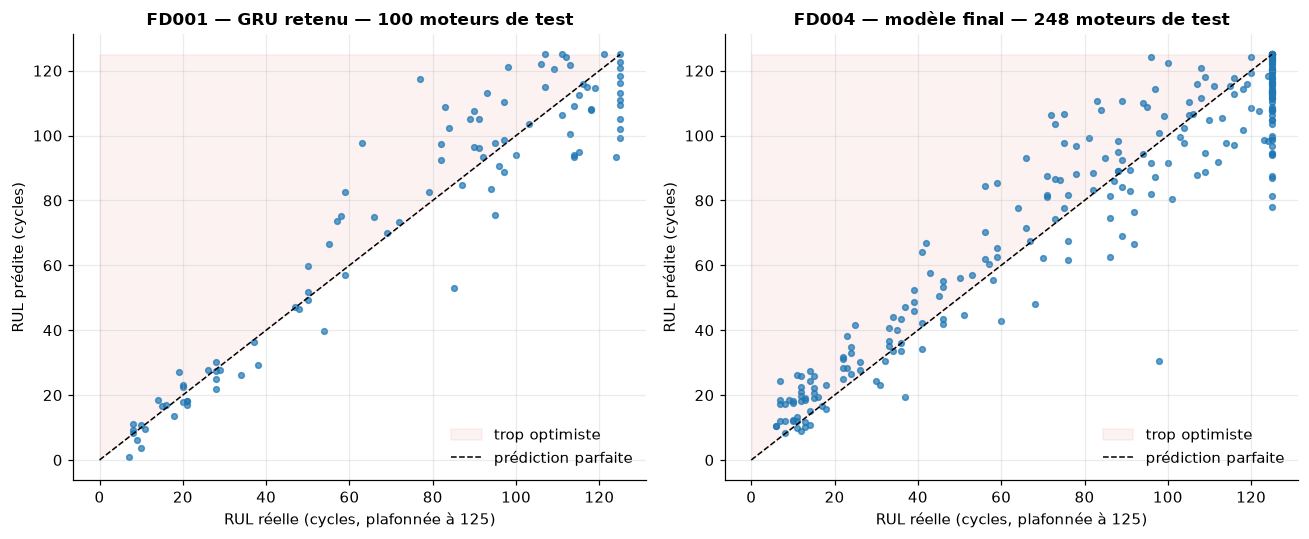

In [5]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))
for ax, (title, name) in zip(axes, [("FD001 — GRU retenu", FINAL_FD001), ("FD004 — modèle final", FINAL_FD004)]):
    w, pred, _ = test_predictions(name, 0)
    ax.fill_between([0, 125], [0, 125], [125, 125], color="tab:red", alpha=0.06, label="trop optimiste")
    ax.scatter(w["rul"], pred, s=14, alpha=0.7)
    ax.plot([0, 125], [0, 125], "k--", linewidth=1, label="prédiction parfaite")
    ax.set_xlabel("RUL réelle (cycles, plafonnée à 125)")
    ax.set_ylabel("RUL prédite (cycles)")
    ax.set_title(f"{title} — {len(pred)} moteurs de test")
    ax.legend(loc="lower right")
plt.tight_layout()
fig.savefig("assets/pred_vs_reel.png", dpi=150, bbox_inches="tight")
plt.show()

Lecture qualitative : la dispersion autour de la diagonale grandit avec la RUL réelle, et une colonne de points apparaît au plafond. La section suivante le chiffre.

## 4. L'erreur dépend-elle de la RUL réelle ? (question 2)

**Attente** : l'erreur devrait être plus faible près de la panne, où les capteurs ont nettement dérivé, que loin de la panne, où ils sont plats (notebook 01).

Calculé sur la validation de FD004, où l'on dispose de toutes les fenêtres de chaque moteur et pas seulement de la dernière.

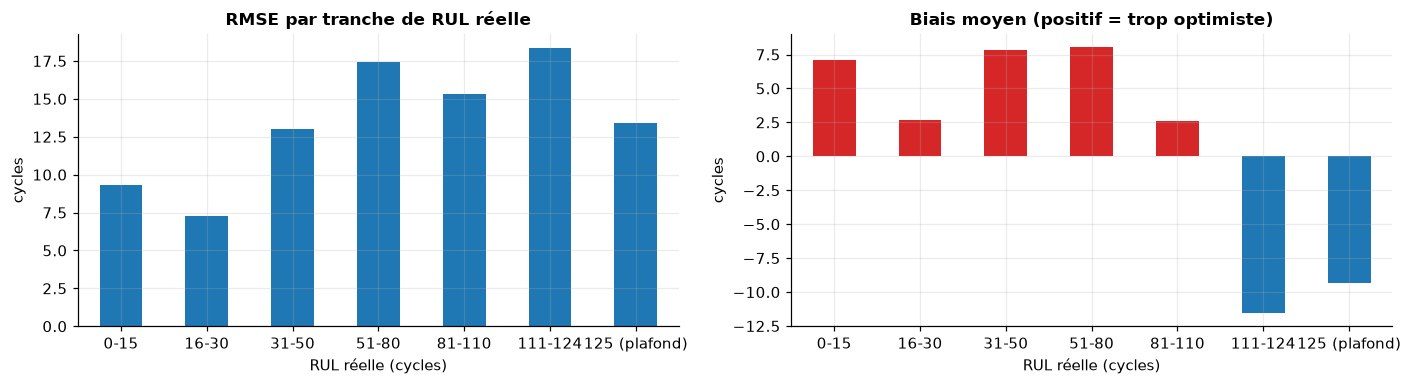

tranche,0-15,16-30,31-50,51-80,81-110,111-124,125 (plafond)
RMSE,9.35,7.24,13.01,17.44,15.3,18.35,13.38
biais,7.10,2.70,7.82,8.02,2.6,-11.54,-9.31
fenêtres,800.00,750.00,1000.00,1500.00,1480.0,642.00,3980.00


RMSE quand la RUL réelle est inférieure ou égale à 30 : **8.4 cycles** ; entre 31 et 124 : 16.0 cycles. L'attente est vérifiée.

Biais moyen quand la RUL réelle est inférieure ou égale à 80 : **+6.8 cycles** (positif = trop optimiste) ; au plafond : -9.3 cycles.

In [6]:
model, bundle, _ = load_run(FINAL_FD004, 0)
cfg, val = bundle["cfg"], bundle["val"]
val_pred, _ = predict(model, val, cfg["rul_max"])

err = pd.DataFrame({"rul": val["rul"], "erreur": (val_pred - val["rul"]).astype(float)})
err["tranche"] = pd.cut(err["rul"], [-1, 15, 30, 50, 80, 110, 124.5, 125],
                        labels=["0-15", "16-30", "31-50", "51-80", "81-110", "111-124", "125 (plafond)"])
par_tranche = err.groupby("tranche", observed=True)["erreur"].agg(
    RMSE=lambda e: np.sqrt(np.mean(e**2)), biais="mean", fenêtres="size").round(2)

fig, axes = plt.subplots(1, 2, figsize=(13, 3.6))
par_tranche["RMSE"].plot.bar(ax=axes[0], rot=0, title="RMSE par tranche de RUL réelle")
par_tranche["biais"].plot.bar(ax=axes[1], rot=0, title="Biais moyen (positif = trop optimiste)",
                              color=np.where(par_tranche["biais"] > 0, "tab:red", "tab:blue"))
for ax in axes:
    ax.set_xlabel("RUL réelle (cycles)")
    ax.set_ylabel("cycles")
plt.tight_layout()
plt.show()
display(par_tranche.T)
pres, loin = err[err["rul"] <= 30]["erreur"], err[(err["rul"] > 30) & (err["rul"] < 125)]["erreur"]
say(f"RMSE quand la RUL réelle est inférieure ou égale à 30 : **{np.sqrt((pres**2).mean()):.1f} cycles** ; entre 31 et 124 : "
    f"{np.sqrt((loin**2).mean()):.1f} cycles. L'attente est {'vérifiée' if (pres**2).mean() < (loin**2).mean() else 'contredite'}.")
say(f"Biais moyen quand la RUL réelle est inférieure ou égale à 80 : **{err[err['rul'] <= 80]['erreur'].mean():+.1f} cycles** "
    f"(positif = trop optimiste) ; au plafond : {err[err['rul'] == 125]['erreur'].mean():+.1f} cycles.")

**Interprétation**
- Un biais positif près de la panne est le défaut le plus gênant en maintenance : le modèle annonce plus de marge qu'il n'en reste. La perte utilisée (MSE) est symétrique ; une perte asymétrique, comme le score NASA, viserait directement ce défaut.
- Le biais négatif près du plafond est en partie mécanique : les prédictions sont bornées à 125, donc elles ne peuvent que sous-estimer une cible égale à 125.

## 5. Trajectoires complètes

RUL prédite à chaque cycle pour 4 moteurs de validation, comparée à la vraie courbe plafonnée. Ces 4 moteurs sont les 4 premiers par numéro : ils n'ont pas été choisis pour leur allure.

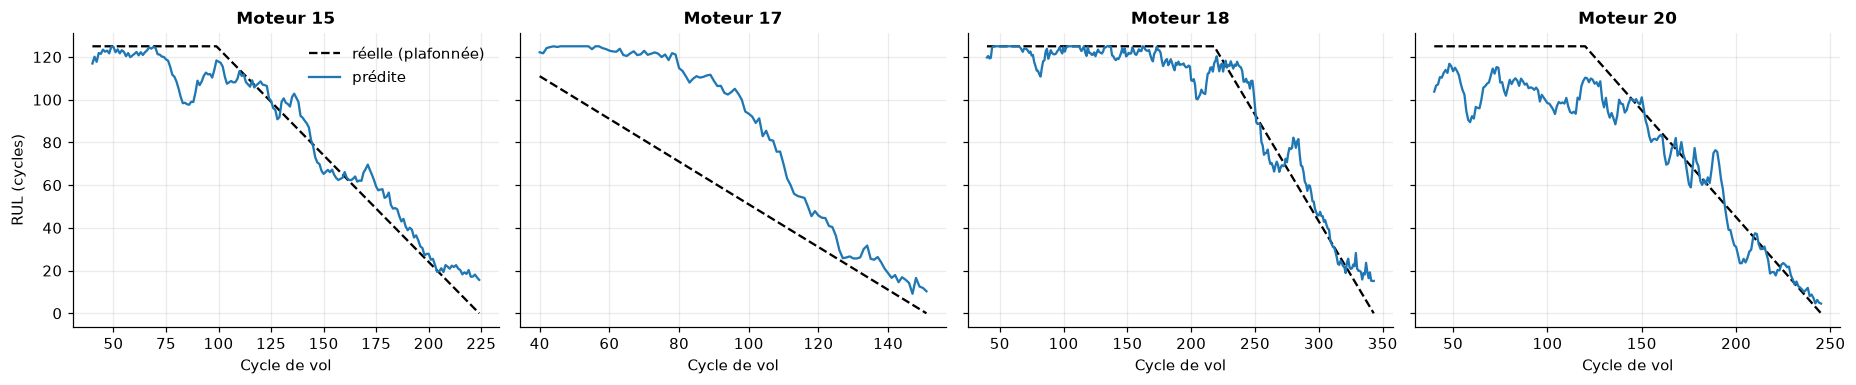

,Moteur 15,Moteur 17,Moteur 18,Moteur 20
durée de vie (cycles),224.0,151.0,343.0,245.0
RMSE sur la trajectoire,9.5,31.0,8.0,15.4


In [7]:
units = np.unique(val["unit"])[:4]
fig, axes = plt.subplots(1, 4, figsize=(17, 3.6), sharey=True)
for ax, unit in zip(axes, units):
    m = val["unit"] == unit
    ax.plot(val["cycle"][m], val["rul"][m], "k--", label="réelle (plafonnée)")
    ax.plot(val["cycle"][m], val_pred[m], label="prédite")
    ax.set_title(f"Moteur {unit}")
    ax.set_xlabel("Cycle de vol")
axes[0].set_ylabel("RUL (cycles)")
axes[0].legend()
plt.tight_layout()
fig.savefig("assets/trajectoires.png", dpi=150, bbox_inches="tight")
plt.show()

display(pd.DataFrame({
    "durée de vie (cycles)": [int(val["cycle"][val["unit"] == u].max()) for u in units],
    "RMSE sur la trajectoire": [regression_metrics(val["rul"][val["unit"] == u], val_pred[val["unit"] == u])["rmse"] for u in units],
}, index=[f"Moteur {u}" for u in units]).round(1).T)

Le modèle reste proche du plafond tant que le moteur est sain, puis suit la descente. Le tableau permet de voir si l'erreur est liée à la durée de vie : un moteur à vie courte passe peu de temps au plafond, et le modèle a moins de cycles pour reconnaître le début de la dégradation.

## 6. Tête de classification (question 3)

Deux façons d'obtenir l'état d'un moteur : la **tête de classification** du modèle, ou la classe **déduite de la RUL prédite** avec les mêmes seuils (30 et 80). Si la tête ne fait pas mieux que le seuil, elle est inutile.

,moyenne,écart-type
"(tête de classification, F1 macro)",0.848,0.020
"(tête de classification, rappel critique)",0.943,0.019
"(déduite de la RUL, F1 macro)",0.848,0.005
"(déduite de la RUL, rappel critique)",0.853,0.008


F1 macro : 0.85 avec la tête, 0.85 en seuillant la RUL. Rappel de la classe critique : **0.94 avec la tête, 0.85 en seuillant la RUL** (moyennes sur 5 graines).

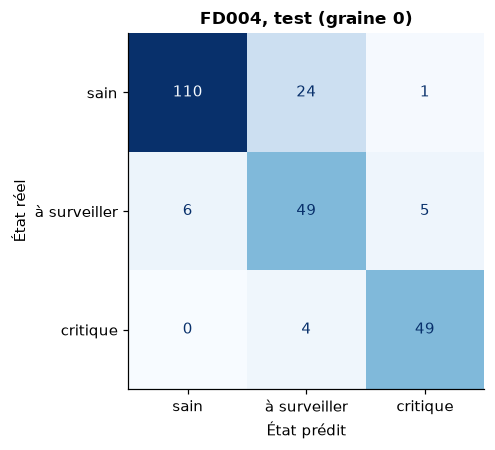

In [8]:
clf = []
for s in SEEDS:
    w, rul_pred, state_pred = test_predictions(FINAL_FD004, s)
    head = classification_metrics(w["state"], state_pred)
    via_rul = classification_metrics(w["state"], rul_to_state(rul_pred))
    clf.append({("tête de classification", "F1 macro"): head["f1_macro"],
                ("tête de classification", "rappel critique"): head["recall_critical"],
                ("déduite de la RUL", "F1 macro"): via_rul["f1_macro"],
                ("déduite de la RUL", "rappel critique"): via_rul["recall_critical"]})
clf = pd.DataFrame(clf)
display(pd.DataFrame({"moyenne": clf.mean(), "écart-type": clf.std()}).round(3))
m = clf.mean()
say(f"F1 macro : {m['tête de classification', 'F1 macro']:.2f} avec la tête, {m['déduite de la RUL', 'F1 macro']:.2f} en seuillant la RUL. "
    f"Rappel de la classe critique : **{m['tête de classification', 'rappel critique']:.2f} avec la tête, "
    f"{m['déduite de la RUL', 'rappel critique']:.2f} en seuillant la RUL** (moyennes sur 5 graines).")

w, _, state_pred = test_predictions(FINAL_FD004, 0)
fig, ax = plt.subplots(figsize=(4.8, 4.2))
ConfusionMatrixDisplay(confusion_matrix(w["state"], state_pred, labels=[0, 1, 2]),
                       display_labels=STATE_NAMES).plot(cmap="Blues", ax=ax, colorbar=False)
ax.grid(False)
ax.set_xlabel("État prédit")
ax.set_ylabel("État réel")
ax.set_title("FD004, test (graine 0)")
plt.show()

**Interprétation** : la tête est entraînée avec des classes pondérées, ce qui la pousse à ne pas manquer la classe critique. Le seuil sur la RUL hérite, lui, du biais optimiste mesuré en section 4. La matrice de confusion montre le prix payé : des moteurs « à surveiller » classés critiques. En maintenance, ce compromis (fausses alertes contre pannes manquées) est un choix métier, pas un choix technique.

## 7. Analyse d'erreurs : les 5 moteurs de test les plus mal prédits (FD004)

In [9]:
w, pred, _ = test_predictions(FINAL_FD004, 0)
analyse = pd.DataFrame({
    "moteur": w["unit"],
    "cycles observés": w["cycle"],
    "RUL réelle (plafonnée)": w["rul"].astype(int),
    "RUL réelle non plafonnée": load_test(cfg).groupby("unit")["rul_linear"].last().to_numpy().astype(int),
    "RUL prédite": pred.astype(float).round(1),
    "erreur": (pred - w["rul"]).astype(float).round(1),
})
display(analyse.reindex(analyse["erreur"].abs().sort_values(ascending=False).index).head(5).set_index("moteur"))

courts = analyse["cycles observés"] < cfg["window"]
print(f"Moteurs de moins de {cfg['window']} cycles (fenêtre complétée) : {courts.sum()}, erreur absolue moyenne "
      f"{analyse.loc[courts, 'erreur'].abs().mean():.1f} contre {analyse['erreur'].abs().mean():.1f} pour l'ensemble")
pires = analyse.reindex(analyse["erreur"].abs().sort_values(ascending=False).index).head(5)
say(f"Sur les 5 pires erreurs, {(pires['erreur'] < 0).sum()} sont des sous-estimations (modèle trop pessimiste) ; "
    f"leur RUL réelle non plafonnée va de {pires['RUL réelle non plafonnée'].min()} à {pires['RUL réelle non plafonnée'].max()} cycles. "
    f"Sur l'ensemble du test, {(analyse['erreur'] > 0).mean():.0%} des prédictions sont trop optimistes.")
long_ = analyse["cycles observés"] >= analyse["cycles observés"].median()
say(f"Erreur absolue moyenne des moteurs observés longtemps (au-dessus de la médiane) : {analyse.loc[long_, 'erreur'].abs().mean():.1f} ; "
    f"des autres : {analyse.loc[~long_, 'erreur'].abs().mean():.1f}.")

,cycles observés,RUL réelle (plafonnée),RUL réelle non plafonnée,RUL prédite,erreur
moteur,,,,,
240,204,98,98,30.6,-67.4
39,214,125,151,77.8,-47.2
34,361,125,126,81.3,-43.7
130,107,125,165,87.0,-38.0
171,355,125,126,87.4,-37.6


Moteurs de moins de 40 cycles (fenêtre complétée) : 16, erreur absolue moyenne 7.4 contre 10.4 pour l'ensemble


Sur les 5 pires erreurs, 5 sont des sous-estimations (modèle trop pessimiste) ; leur RUL réelle non plafonnée va de 98 à 165 cycles. Sur l'ensemble du test, 48% des prédictions sont trop optimistes.

Erreur absolue moyenne des moteurs observés longtemps (au-dessus de la médiane) : 9.5 ; des autres : 11.4.

**Ce que cette analyse établit, et ce qu'elle n'établit pas**
- Elle établit le **type** d'erreur le plus grave en amplitude et son sens.
- Elle n'en établit pas la **cause**. Deux pistes non vérifiées : le mode de panne (FD004 en a deux, mais le jeu ne dit pas lequel touche chaque moteur) et le profil de vol du moteur (la répartition de ses cycles entre régimes).
- Une vérification possible, non faite : regrouper les trajectoires par forme de dégradation (clustering) et regarder si les erreurs se concentrent dans un groupe.

## 8. Interprétabilité : importance par permutation (question 4)

On mélange un capteur entre les fenêtres de validation et on mesure la hausse de RMSE. Un capteur dont le mélange ne change rien n'est pas utilisé par le modèle.

**Attente** (notebook 01) : s11 et s4, les plus corrélés à la RUL, devraient ressortir.

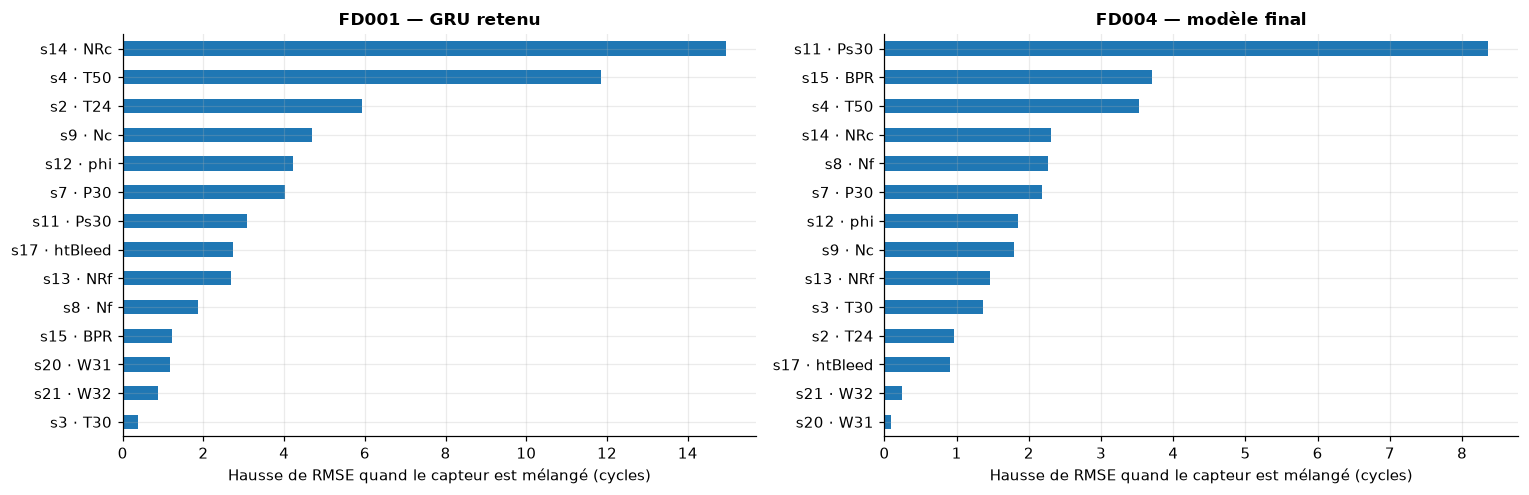

**FD001** — trois capteurs les plus importants : s14 (+14.9), s4 (+11.8), s2 (+5.9). Capteurs attendus : s11 (rang 7), s4 (rang 2) sur 14.

**FD004** — trois capteurs les plus importants : s11 (+8.4), s15 (+3.7), s4 (+3.5). Capteurs attendus : s11 (rang 1), s4 (rang 3) sur 14.

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.6))
for ax, (title, name) in zip(axes, [("FD001 — GRU retenu", FINAL_FD001), ("FD004 — modèle final", FINAL_FD004)]):
    m, b, _ = load_run(name, 0)
    imp = pd.Series(permutation_importance(m, b["val"], b["features"], b["cfg"]["rul_max"])).sort_values()
    imp.index = [f"{s} · {SENSOR_NAMES[s].split(' — ')[0]}" for s in imp.index]
    imp.plot.barh(ax=ax)
    ax.set_title(title)
    ax.set_xlabel("Hausse de RMSE quand le capteur est mélangé (cycles)")
plt.tight_layout()
fig.savefig("assets/importance.png", dpi=150, bbox_inches="tight")
plt.show()

for title, name in [("FD001", FINAL_FD001), ("FD004", FINAL_FD004)]:
    m, b, _ = load_run(name, 0)
    imp = pd.Series(permutation_importance(m, b["val"], b["features"], b["cfg"]["rul_max"])).sort_values(ascending=False)
    rangs = ", ".join(f"{s} (rang {imp.index.get_loc(s) + 1})" for s in ["s11", "s4"])
    say(f"**{title}** — trois capteurs les plus importants : " + ", ".join(f"{s} (+{v:.1f})" for s, v in imp.head(3).items())
        + f". Capteurs attendus : {rangs} sur {len(imp)}.")

**Interprétation**
- Quand un capteur attendu ressort, le modèle s'appuie sur un signal que la physique explique : c'est un argument de confiance.
- Quand un capteur peu corrélé à la RUL ressort, deux lectures sont possibles : le modèle exploite un lien non linéaire que la corrélation ne voit pas, ou il s'appuie sur une particularité du simulateur. On ne peut pas trancher ici.
- Limite de la méthode : avec des capteurs corrélés entre eux, l'importance se répartit mal. Mélanger l'un laisse l'information disponible dans l'autre.

## 9. Menaces à la validité

Ce que ces résultats ne permettent **pas** d'affirmer, et pourquoi.

| Menace | Conséquence | Ce qui a été fait, ce qui reste |
| --- | --- | --- |
| Données **simulées** (C-MAPSS) | Rien ne garantit que ces scores se transposent à de vrais moteurs | Aucune parade possible ici ; à dire explicitement |
| Un seul découpage train / validation pour les choix | Les écarts-types sur 5 graines sous-estiment l'incertitude | Validation croisée à 5 plis pour la comparaison principale (notebook 03) ; pas pour chaque ablation |
| Hyperparamètres choisis et scores lus sur la même validation | Scores de validation optimistes | Le jeu de test, jamais utilisé pour un choix, sert d'arbitre |
| Scores de test affichés plusieurs fois pendant la mise au point | Risque d'ajustement inconscient | Aucun hyperparamètre modifié après ; signalé |
| Validation mesurée sur toutes les fenêtres, test sur la dernière seulement | Les deux scores ne mesurent pas la même chose | Non corrigé : les scores de validation et de test ne sont pas directement comparables |
| Réglage inégal des modèles (grille de 36 essais pour le LSTM, 9 pour la forêt, aucun pour le boosting) | La comparaison réseau / baseline peut pencher d'un côté | Forêt réglée ; un réglage plus poussé des deux côtés reste à faire |
| Plafond de RUL à 125, appliqué aussi à la vérité de test | Scores non comparables aux articles qui ne plafonnent pas | Effet chiffré en section 2 |
| Branche contexte limitée au régime du dernier cycle | « Le contexte n'apporte rien » ne vaut que pour cette conception | Signalé ; d'autres encodages non testés |
| FD002 et FD003 non traités | Pas de mesure de généralisation entre sous-ensembles | Reste à faire |

## 10. Conclusion : réponses aux quatre questions

In [11]:
lignes = []
for subset, label in FINALS.items():
    r = scores[(scores["jeu"] == subset) & (scores["modèle"] == label)].iloc[0]
    sens = "forêt meilleure" if r.ecart_bas > 0 else "réseau meilleur" if r.ecart_haut < 0 else "écart non significatif"
    lignes.append({"question": f"1. Réseau contre Random Forest réglé ({subset})",
                   "réponse": f"écart de RMSE {r.ecart_rf:+.2f} [{r.ecart_bas:+.2f} ; {r.ecart_haut:+.2f}] : {sens}"})
lignes.append({"question": "2. Plus précis près de la panne ?",
               "réponse": f"RMSE {np.sqrt((pres**2).mean()):.1f} si RUL ≤ 30, contre {np.sqrt((loin**2).mean()):.1f} entre 31 et 124"})
lignes.append({"question": "3. La tête de classification sert-elle ?",
               "réponse": f"rappel critique {clf.mean()['tête de classification', 'rappel critique']:.2f} contre "
                          f"{clf.mean()['déduite de la RUL', 'rappel critique']:.2f} en seuillant la RUL"})
lignes.append({"question": "4. Les capteurs attendus sont-ils utilisés ?", "réponse": f"FD004 : {rangs}"})
pd.set_option("display.max_colwidth", None)
pd.DataFrame(lignes).set_index("question")

,réponse
question,
1. Réseau contre Random Forest réglé (FD001),écart de RMSE +0.49 [-0.94 ; +2.02] : écart non significatif
1. Réseau contre Random Forest réglé (FD004),écart de RMSE +0.07 [-0.84 ; +0.97] : écart non significatif
2. Plus précis près de la panne ?,"RMSE 8.4 si RUL ≤ 30, contre 16.0 entre 31 et 124"
3. La tête de classification sert-elle ?,rappel critique 0.94 contre 0.85 en seuillant la RUL
4. Les capteurs attendus sont-ils utilisés ?,"FD004 : s11 (rang 1), s4 (rang 3)"


**Pistes d'amélioration**, par ordre de priorité
1. Corriger l'optimisme près de la panne : perte asymétrique, ou marge de sécurité sur la prédiction.
2. Comprendre pourquoi la forêt résiste : donner au réseau les mêmes caractéristiques de fenêtre en entrée, ou tester un CNN 1D.
3. Fournir un intervalle d'incertitude par moteur (MC Dropout) plutôt qu'une seule valeur.
4. Mesurer la généralisation : entraîner sur FD004, tester sur FD002.